# B03-GN — Thuận

Phân công khớp chính xác mốc `2026-11-17T21:00:00.000Z` trong workbook nguồn.
Ngày giờ Việt Nam: **04:00 ngày 18/11/2026**. Mã thư mục giữ ngày của mốc UTC.

Cấu hình: `B03`, `GNNClustering`. Nguồn duy nhất:
`data/raw/Online Retail.xlsx`, SHA-256 `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d`.

Notebook mặc định đọc kết quả đã chạy. Đổi `RUN_AGAIN = True` để dựng lại từ raw,
quét tham số và ghi lại **chỉ thư mục kết quả của thí nghiệm này**.
Mọi nhãn cụm gắn với CustomerID; Monetary là giá trị mua lịch sử GBP.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "B03-GN"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,B03-GN
Mô hình,GNNClustering
Khách,4327
Số chiều đầu vào,2
Biến đổi,yeo_johnson
Scaler,StandardScaler
PCA,0.9


{
  "configuration": "B03",
  "transform": "yeo_johnson",
  "scaler": "StandardScaler",
  "pca_requested": 0.9,
  "model_input_dimensions": 2,
  "pca_explained_variance_ratio": [
    0.747199250486804,
    0.18624045095611919
  ],
  "pca_explained_variance_total": 0.9334397014429232,
  "pca_components": [
    [
      -0.5156021665920826,
      0.6164223596878546,
      0.5951284569590062
    ],
    [
      0.8468448582072837,
      0.26089559848838345,
      0.46345147838503453
    ]
  ],
  "yeo_johnson_lambdas": [
    0.1252167156747613,
    -0.7703863985147704,
    -0.07825295399629893
  ]
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
k,10
n_clusters,10
noise_pct,0.0
smallest_cluster,238
largest_cluster_pct_all,14.143749
silhouette,0.340958
dbi,0.961241
chi,1338.192819
inertia,2726.800662
eligible,True


,k,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,inertia,eligible
0,2,2,0.0,1864,56.921655,0.192325,2.163867,838.014174,8656.821722,True
1,3,3,0.0,1240,37.231338,0.243890,1.679607,939.277707,7204.256957,True
2,4,4,0.0,790,29.905246,0.285316,1.397201,1057.610381,5959.908647,True
3,5,5,0.0,719,22.995147,0.302269,1.236064,1124.207209,5064.648957,True
4,6,6,0.0,561,19.875202,0.319170,1.095143,1231.289998,4261.912808,True
5,7,7,0.0,450,18.003235,0.331323,1.063698,1282.653830,3715.363208,True
6,8,8,0.0,337,16.269933,0.332570,1.008993,1301.485399,3323.544208,True
7,9,9,0.0,279,16.940143,0.336360,0.974617,1304.397382,3024.627149,True
8,10,10,0.0,238,14.143749,0.340958,0.961241,1338.192819,2726.800662,True


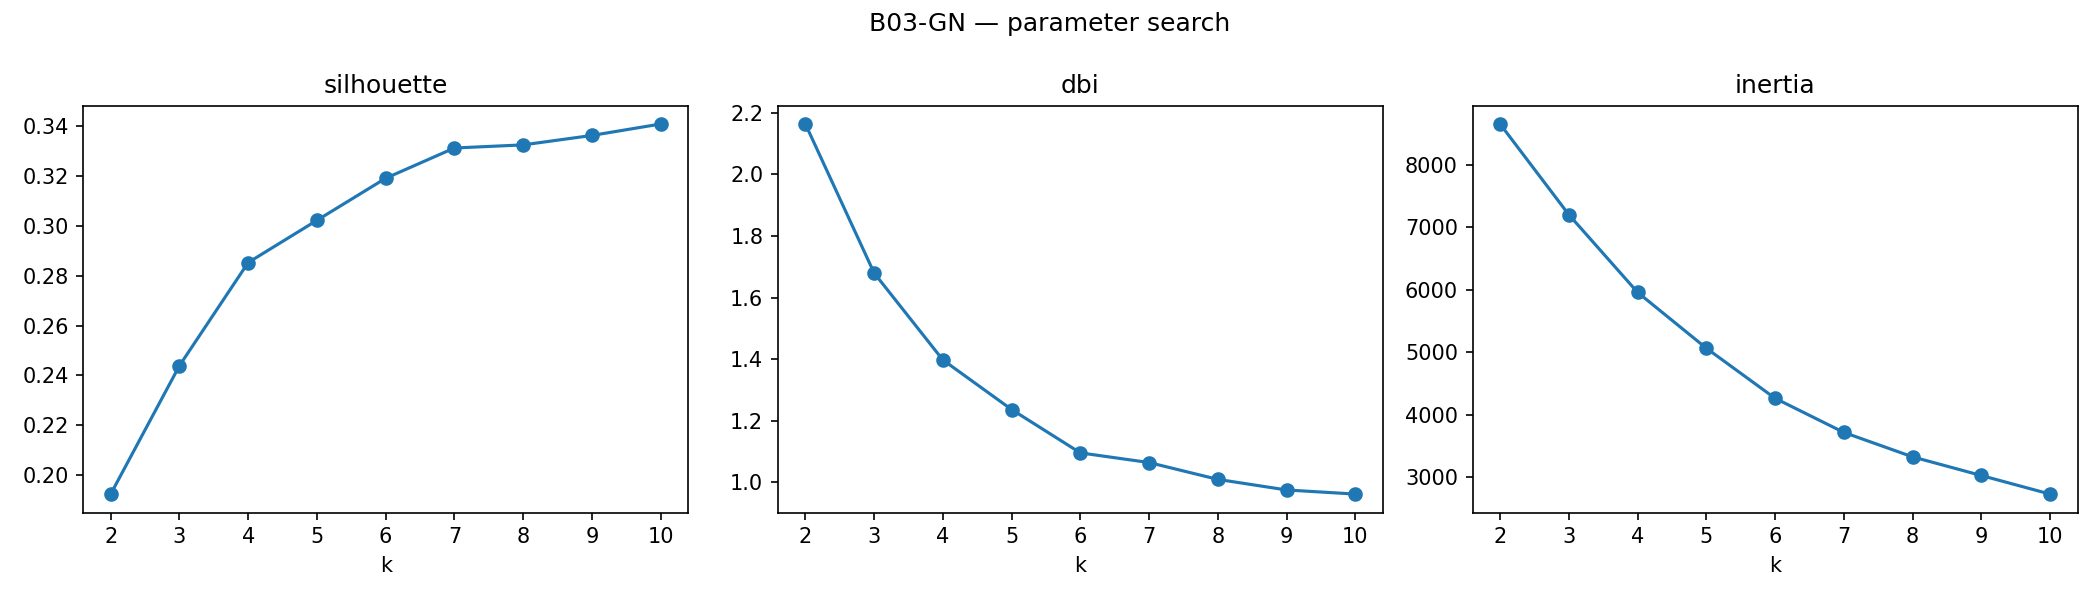

{
  "architecture": "GCN(input,32)-ReLU-GCN(32,8); inner-product edge decoder",
  "graph": "symmetrized union 15-nearest-neighbor Euclidean graph from PCA/model input",
  "message_passing": "D^-1/2 (A_train + I) D^-1/2; validation/test positives removed",
  "train_positive_edges": 29833,
  "validation_positive_edges": 3729,
  "test_positive_edges": 3729,
  "epochs_run": 200,
  "best_epoch": 199,
  "initial_validation_bce": 0.6894039511680603,
  "best_validation_bce": 0.4633237421512604,
  "initial_validation_diagnostic": {
    "roc_auc": 0.7544971065642578,
    "average_precision": 0.7059704923388064
  },
  "validation_link_metrics": {
    "roc_auc": 0.9584522705896201,
    "average_precision": 0.9391253457862779
  },
  "test_link_metrics": {
    "roc_auc": 0.9627712634212751,
    "average_precision": 0.946442141984229
  },
  "test_usage": "evaluated once after validation checkpoint selection; never used for training or cluster-k selection",
  "negative_sampling": "1:1 uniform non-edge

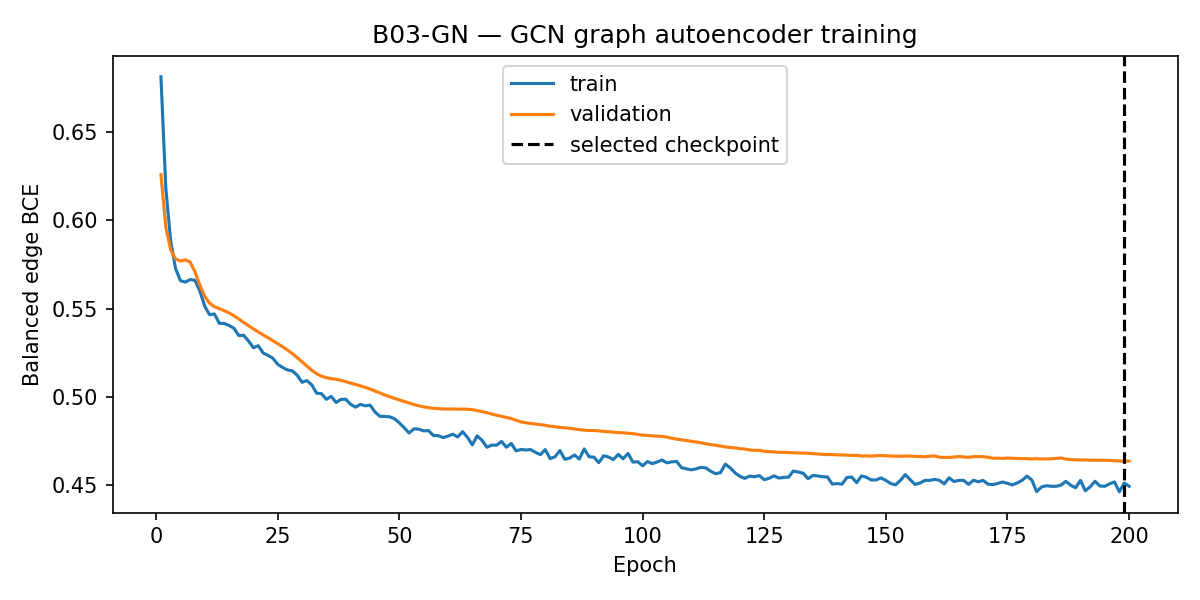

,epoch,train_link_bce,validation_link_bce
0,1,0.681622,0.626023
1,2,0.618419,0.596217
2,3,0.588319,0.583254
3,4,0.572747,0.578227
4,5,0.565819,0.576916
...,...,...,...
195,196,0.450462,0.463695
196,197,0.451566,0.463512
197,198,0.445917,0.463428
198,199,0.450905,0.463324


In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,1
1,12348,76,4,1437.24,6
2,12349,19,1,1457.55,9
3,12350,311,1,294.40,4
4,12352,37,7,1385.74,6
5,12353,205,1,89.00,4
6,12354,233,1,1079.40,0
7,12355,215,1,459.40,4
8,12356,23,3,2487.43,3
9,12357,34,1,6207.67,3


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,0,312,213.0,2.0,983.120,444425.991,7.210538,5.280860
1,1,314,4.0,13.5,4805.420,3663552.980,7.256760,43.531905
2,2,266,20.0,1.0,176.615,53690.190,6.147446,0.637970
3,3,572,20.0,5.0,1430.090,962680.841,13.219321,11.438986
4,4,612,274.0,1.0,223.470,152068.480,14.143749,1.806943
5,5,238,4.0,4.0,929.170,249080.750,5.500347,2.959684
6,6,487,47.0,6.0,2647.590,2079924.170,11.254911,24.714549
7,7,547,71.0,1.0,234.340,145640.691,12.641553,1.730565
8,8,568,97.0,2.0,634.020,410345.490,13.126878,4.875901
9,9,411,23.0,2.0,583.430,254378.790,9.498498,3.022638


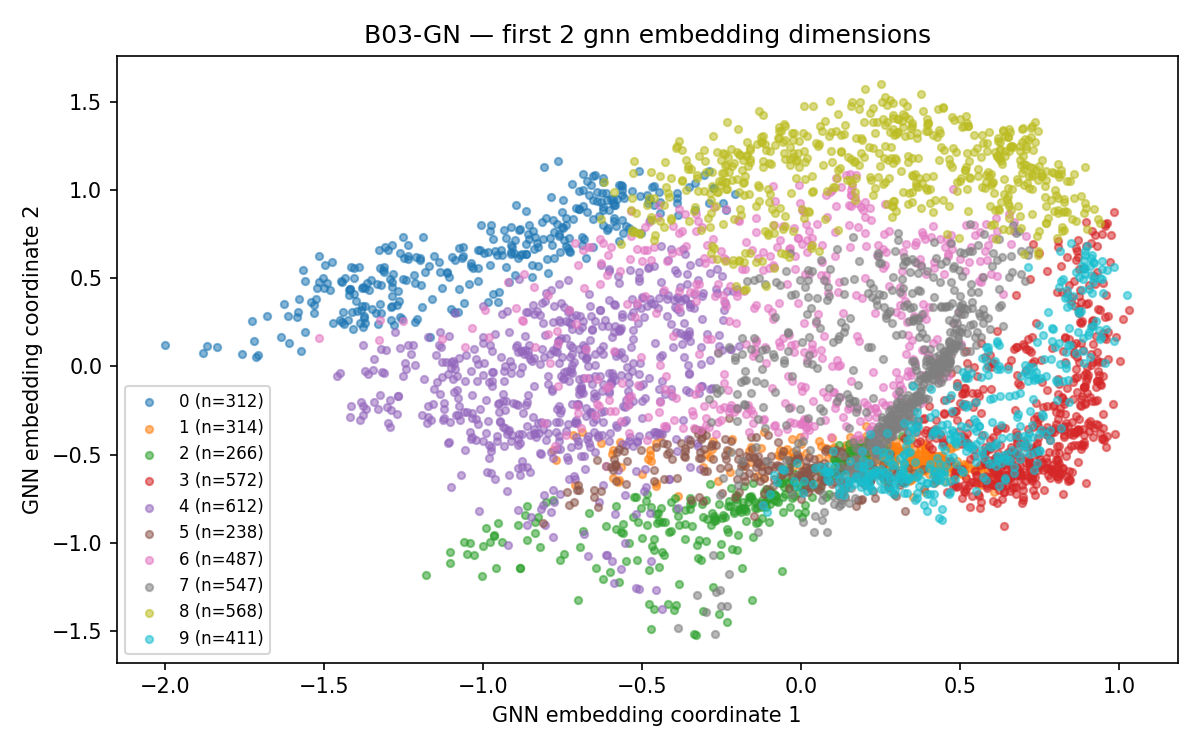

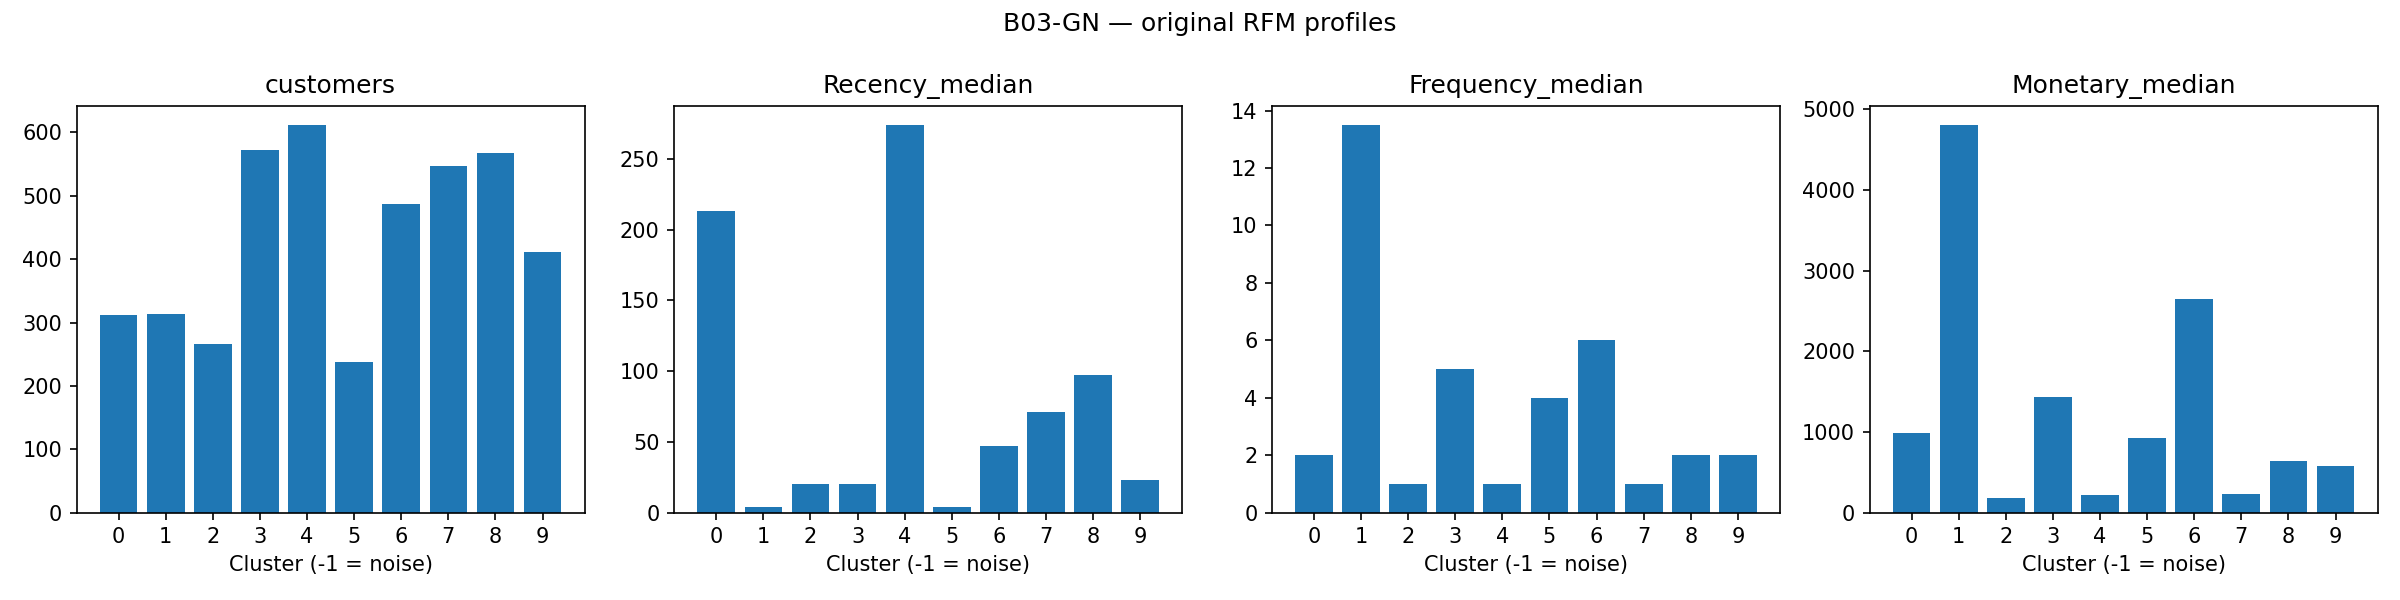

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


{
  "parent_configuration": "B01",
  "purpose": "fixed-parameter preprocessing diagnostic, not a tuned parent experiment",
  "target_dimensions": 2,
  "parent_dimensions": 2,
  "ari": 0.777571861189575,
  "target_common_rfm_scores": {
    "n_clusters": 10,
    "noise_pct": 0.0,
    "smallest_cluster": 238,
    "largest_cluster_pct_all": 14.143748555581235,
    "silhouette": 0.002245555578232349,
    "dbi": 1.8662939017620885,
    "chi": 400.70775033849276
  },
  "parent_common_rfm_scores": {
    "n_clusters": 10,
    "noise_pct": 0.0,
    "smallest_cluster": 265,
    "largest_cluster_pct_all": 14.444187658886063,
    "silhouette": -0.0067650438217739,
    "dbi": 2.1675283838120043,
    "chi": 432.5028050313084
  },
  "parent_input_scores": {
    "n_clusters": 10,
    "noise_pct": 0.0,
    "smallest_cluster": 265,
    "largest_cluster_pct_all": 14.444187658886063,
    "silhouette": 0.28827130991004285,
    "dbi": 1.075769444117844,
    "chi": 2871.4811310439
  },
  "parent_preprocessing

,Giá trị
n_clusters,10.000000
noise_pct,0.000000
smallest_cluster,238.000000
largest_cluster_pct_all,14.143749
silhouette,0.002246
dbi,1.866294
chi,400.707750


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.
- Transductive GNN: graph/embeddings apply to the fitted customers and their original order; unseen nodes require graph reconstruction and retraining.
- Held-out link prediction evaluates reconstruction of an RFM-derived graph, not business outcomes, customer value prediction, or segmentation ground truth.
- Only one fixed random seed and one GNN architecture are evaluated; graph and architecture choices are explicit implementation assumptions.

## Kiểm tra mô hình đã lưu

In [6]:
import joblib
pipeline = joblib.load(OUT / "pipeline.joblib")
X = labels[runner.FEATURES]
Z = pipeline["preprocessing"].transform(X)
saved = pd.read_csv(OUT / "model_input.csv").filter(like="input_").to_numpy()
np.testing.assert_allclose(Z, saved, atol=1e-9, rtol=0)
if params["actual_model"] != "DBSCAN":
    np.testing.assert_array_equal(pipeline.predict(X), labels.cluster)
else:
    np.testing.assert_array_equal(pipeline["model"].labels_, labels.cluster)
    print("DBSCAN không có predict cho khách mới; labels_ gắn với đúng thứ tự khách khi fit.")
print("PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.")


PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.
